# Modelado Estadístico Inferencial y Predictivo de Material Particulado ($MP_{10}$ y $PM_{2.5}$) en la Estación Kingston College
## Avance 1: Diseño del Estudio, EDA en 5 Etapas y Relaciones entre Variables

* **Universidad:** Universidad del Desarrollo — Facultad de Ingeniería
* **Curso:** Análisis de Datos e Inferencia Estadística
* **Profesor Guía:** Danilo Gómez Correa
* **Integrantes:** Javier Benavides Ortega, Cristóbal Montoya Toledo
* **Fecha de Entrega:** 26 de Octubre de 2026
* **Ubicación:** Concepción, Región del Biobío, Chile

---

## Índice General (Alineado con las Clases del Curso)
1. **Pregunta de Investigación e Hipótesis** (`Hipotesis.pdf`)
   - 1.1 Contextualización del Problema
   - 1.2 Pregunta de Investigación
   - 1.3 Formulación de Hipótesis, Errores Tipo I ($\alpha$) y Tipo II ($\beta$), y Criterio del Valor-$p$
2. **Revisión de Literatura**
   - 2.1 Síntesis Crítica y Artículos de Referencia
   - 2.2 Identificación del Vacío de Conocimiento (Gap)
3. **Metodología y Las 5 Etapas del EDA** (`EDA_5_Etapas.pdf`)
   - 3.1 Tipo de Análisis y Fuente de Datos (16 Datasets SINCA = $893.398$ filas)
   - 3.2 **Etapa 1 del EDA:** Análisis Descriptivo Individual ($\bar{z}, z_m, Q_1, Q_3, IQR, s, CV, k_s$) y Tabla de Frecuencias con **Regla de Sturges**
   - 3.3 **Etapa 2 del EDA:** Taxonomía y Ajuste de Variables
   - 3.4 **Etapa 3 del EDA:** Identificación y Tratamiento de Datos Nulos (Mecanismos MCAR, MAR, MNAR)
   - 3.5 **Etapa 4 del EDA:** Detección de Datos Atípicos ($RIC$, *Z-score*, **Test de Grubbs**), Medidas Robustas ($\text{MAD}$) y **Winsorización** (Comparación Antes vs. Después)
4. **Diagrama Metodológico (OBLIGATORIO)**
5. **Etapa 5 del EDA: Análisis de Relaciones entre Variables y Modelos Lineales**
   - 5.1 **Pruebas de Bondad de Ajuste** (`Bondad_de_Ajuste.pdf`): Kolmogórov-Smirnov ($D, D^+, D^-, D_{\alpha}$), Anderson-Darling ($A^2$) y Shapiro-Wilk ($W$)
   - 5.2 **Relación Numérica vs. Numérica y Regresión Lineal Simple/Múltiple** (`EDA_5_Etapas.pdf` y `RLM.pdf`): Covarianza ($C_{xy}$), Pearson ($r$ y prueba $t$), Spearman ($r_s$), Kendall ($\tau$), Estimador EMCO ($\hat{\beta} = (X^T X)^{-1} X^T Y$), Verificación de Propiedades y 6 Supuestos de Gauss-Markov, Tabla ANOVA de la Regresión ($SSR, SSE, SST, F_c$), $R^2$ y $R_a^2$, e Inferencia / Intervalos de Confianza de $\beta_j$
   - 5.3 **Relación Numérica vs. Categórica** (`ANOVA_ML.pdf` y `EDA_5_Etapas.pdf`): Modelo $Y_{ij} = \mu_i + e_{ij}$, Descomposición $SCT = SC\text{Trat} + SCE$, Tabla ANOVA Completa, Magnitud de Efecto ($\eta^2$), **Procedimiento Post-Hoc de Tukey** y Prueba de Kruskal-Wallis ($H$)
   - 5.4 **Relación Categórica vs. Categórica** (`EDA_5_Etapas.pdf`): Tabla de Contingencia ($O_{ij}$ vs $E_{ij}$), Prueba $\chi^2$ de Independencia y $V$ de Cramér
   - 5.5 **Tabla Resumen Oficial (OBLIGATORIA)**
6. **Referencias Bibliográficas**

In [1]:
# [Configuración Inicial / Google Colab] Descomprime automáticamente colab_pack.zip si estás en la nube:
import os, zipfile
if not os.path.exists('Datos') and os.path.exists('colab_pack.zip'):
    with zipfile.ZipFile('colab_pack.zip', 'r') as z:
        z.extractall('.')
    print('✓ Pack descomprimido en Google Colab: carpetas Datos/ y graficos_png/ listas.')
elif os.path.exists('Datos'):
    print('✓ Carpeta Datos/ detectada correctamente.')

✓ Carpeta Datos/ detectada correctamente.


---
## 1. Pregunta de Investigación e Hipótesis

### 1.1. Contextualización del Problema
En el Gran Concepción (Región del Biobío, Chile), la concentración de material particulado atmosférico presenta incrementos críticos durante el periodo otoño-invierno. El material particulado fino ($PM_{2.5}$, partículas con diámetro aerodinámico $\le 2.5\,\mu\text{m}$) constituye una fracción interna del material particulado grueso ($MP_{10}$, $\le 10\,\mu\text{m}$), es decir, $PM_{2.5} \subseteq MP_{10}$. En centros urbanos del centro-sur del país, las fuentes de combustión residencial y vehicular emiten ambas fracciones de manera co-localizada. La estación de monitoreo continuo **Kingston College** (red SINCA) registra de manera representativa estas dinámicas. Determinar en qué medida el contaminante grueso ($MP_{10}$) permite predecir los niveles de $PM_{2.5}$ es fundamental para estimar concentraciones finas a partir de macro-mediciones y caracterizar su comportamiento estacional.

### 1.2. Pregunta de Investigación
> **¿En qué medida los niveles diarios de material particulado grueso ($MP_{10}$) predicen la concentración de material particulado fino ($PM_{2.5}$) en la estación Kingston College (Concepción) durante el período de estudio, y cómo varía esta relación según la estación del año y el tipo de día (laboral vs. fin de semana)?**

### 1.3. Formulación de Hipótesis y Criterio de Decisión (`Hipotesis.pdf`)
Siguiendo la estructura formal de pruebas de hipótesis vista en clases (**Profesor Danilo Gómez Correa, `Hipotesis.pdf`**):

1. **Hipótesis Nula ($H_0$):** Afirmación sobre el parámetro poblacional que representa el *status quo* (ausencia de efecto):
   $$H_0: \beta_1 = 0 \quad (\text{y } \rho = 0)$$
   *(No existe relación lineal estadísticamente significativa entre $MP_{10}$ y $PM_{2.5}$).*
2. **Hipótesis Alternativa ($H_1$):** Propuesta que representa el efecto que se busca demostrar:
   $$H_1: \beta_1 \neq 0 \quad (\text{o unilateralmente } \beta_1 > 0, \, \rho > 0)$$
3. **Errores y Potencia de la Prueba:**
   * **Error Tipo I ($\alpha$):** $\alpha = \Pr(\text{rechazar } H_0 \mid H_0 \text{ verdadera})$. Se fija en $\alpha = 0.05$ ($5\%$).
   * **Error Tipo II ($\beta$):** $\beta = \Pr(\text{no rechazar } H_0 \mid H_0 \text{ falsa})$.
   * **Potencia del test ($\gamma$):** $\gamma = 1 - \beta$ (probabilidad de rechazar correctamente $H_0$ cuando es falsa).
4. **Escala de Evidencia según el Valor-$p$ (`Hipotesis.pdf`, diapositiva 23):**
   * $(v - p) < 0.01$: Existe **evidencia muy fuerte** contra $H_0$.
   * $0.01 < (v - p) < 0.05$: Existe **evidencia fuerte** contra $H_0$.
   * $0.05 < (v - p) < 0.10$: Existe **evidencia débil** contra $H_0$.
   * $(v - p) > 0.10$: **No se rechaza $H_0$** (evidencia insuficiente contra $H_0$).

---
## 2. Revisión de Literatura

### 2.1. Síntesis Crítica y Artículos de Referencia
Para fundamentar el diseño del estudio se analizaron investigaciones recientes y reportes oficiales del monitoreo de calidad del aire en Chile (priorizando literatura entre 2019 y 2026):

1. **Cereceda-Balic et al. (2020) [1]:** Caracterizan químicamente el material particulado en el centro-sur de Chile, demostrando que durante los meses fríos el $PM_{2.5}$ representa entre el $65\%$ y $80\%$ de la masa total de $MP_{10}$ debido a la combustión de biomasa. Este antecedente aporta la base física que sustenta la magnitud de la pendiente $\beta_1 \approx 0.70$ esperada en nuestro modelo de regresión.
2. **Saide et al. (2016) [5]:** Evalúan el control meteorológico sobre los episodios de contaminación en la cuenca de Concepción, explicando cómo las inversiones térmicas de subsidencia y el estancamiento atmosférico provocan saturación de partículas independientemente del día de la semana. Esto fundamenta el resultado de independencia hallado en nuestra prueba de Chi-cuadrado.
3. **Gramsch et al. (2021) [2]:** Utilizan los confinamientos del año 2020 como experimento natural en Chile, evidenciando que la reducción del flujo vehicular laboral no disminuyó significativamente el $PM_{2.5}$ invernal en ciudades del centro-sur debido al rol dominante de la calefacción domiciliaria. Este hallazgo respalda la preponderancia del factor estacional sobre el tipo de día en nuestro análisis.
4. **Superintendencia del Medio Ambiente - SMA (2024) [6]:** Informe de evaluación técnica sobre el cumplimiento normativo en redes de calidad del aire, estableciendo protocolos de validación jerárquica de registros y tratamiento de discontinuidades instrumentales. Aporta el criterio técnico para depurar anomalías de sensores en SINCA.
5. **Instituto Nacional de Estadísticas - INE (2026) [3]:** Informe Anual de Estadísticas del Medio Ambiente 2025 (publicado en enero de 2026), que sistematiza los registros oficiales de calidad del aire a nivel nacional y clasifica formalmente la estación Kingston College dentro de la red del Biobío.
6. **Ministerio del Medio Ambiente - MMA (2019) [4]:** Plan de Prevención y Descontaminación Atmosférica (PPDA) para el Gran Concepción (D.S. N° 6/2019), el cual fija los umbrales de concentración diaria para clasificar la calidad del aire en episodios de Alerta, Preemergencia y Emergencia.

### 2.2. Identificación del Vacío de Conocimiento (Gap)
Si bien existen reportes descriptivos gubernamentales agregados por año en la región, **existe un vacío de análisis cuantitativo continuo actualizado en la estación Kingston College a nivel diario y multivariable**. Muchos estudios previos se limitaron a campañas de corta duración o al uso de datos mensuales debido a la dispersión de registros brutos. Este proyecto aborda dicho vacío procesando una base integrada de **16 datasets (8 horarios y 8 promedios mensuales/diarios)** con más de 17 años de monitoreo, aplicando rigurosamente la **Metodología de las 5 Etapas del EDA** y los modelos lineales del curso.

---
## 3. Metodología y Desarrollo de las Etapas 1 a 4 del EDA (`EDA_5_Etapas.pdf`)

### 3.1. Fuente de Datos, Período de Muestreo y Volumen
* **Fuente de Datos:** Registros públicos de la estación continua **Kingston College (Concepción)** del Sistema de Información Nacional de Calidad del Aire (SINCA), Ministerio del Medio Ambiente.
* **Estructura de Datasets Analizados:** El estudio recopila **16 datasets en total**:
  1. **8 datasets de resolución horaria** (*hora a hora*, totalizando $851.946$ filas para $CO$, $MP_{10}$, $PM_{2.5}$, $NO$, $NO_2$, $NO_x$, $O_3$, $SO_2$).
  2. **8 datasets de resolución diaria/mensual** agregada (totalizando $41.452$ filas de series históricas consolidadas).
  La integración global de los 16 archivos suma **$893.398$ filas** (período agosto 2009 – octubre 2026).

In [2]:
# Auditoría de volumen de los 16 datasets en Datos/ y funciones base de lectura
import os, csv, math, statistics
from datetime import datetime
from collections import defaultdict

datos_dir = 'Datos' if os.path.isdir('Datos') else '.'
archivos_csv = sorted([f for f in os.listdir(datos_dir) if f.endswith('.csv')])

filas_horarias, filas_agregadas = 0, 0
print(f"{'Archivo CSV':<20} | {'Resolución':<16} | {'Filas de Datos':>14}")
print("-" * 56)
for fname in archivos_csv:
    with open(os.path.join(datos_dir, fname), 'r', encoding='utf-8', errors='replace') as f:
        n_rows = max(0, sum(1 for _ in f) - 1)
    if '_hora' in fname.lower():
        filas_horarias += n_rows
        tipo = 'Horaria'
    else:
        filas_agregadas += n_rows
        tipo = 'Diaria/Mensual'
    print(f"{fname:<20} | {tipo:<16} | {n_rows:>14,}")
print("-" * 56)
print(f"Sub-total series horarias  : {filas_horarias:>10,} filas")
print(f"Sub-total series agregadas : {filas_agregadas:>10,} filas")
print(f"TOTAL CONSOLIDADO (16 CSV) : {filas_horarias + filas_agregadas:>10,} filas")

Archivo CSV          | Resolución       | Filas de Datos
--------------------------------------------------------
CO.csv               | Diaria/Mensual   |          6,277
CO_hora.csv          | Horaria          |        150,671
MP10.csv             | Diaria/Mensual   |            206
MP10_hora.csv        | Horaria          |          6,275
MP2_5.csv            | Diaria/Mensual   |          6,277
MP2_5_hora.csv       | Horaria          |        150,671
NO.csv               | Diaria/Mensual   |          6,276
NO2.csv              | Diaria/Mensual   |          6,276
NO2_hora.csv         | Horaria          |        150,647
NOX.csv              | Diaria/Mensual   |          6,277
NO_hora.csv          | Horaria          |        150,647
NOx_hora.csv         | Horaria          |        150,671
O3.csv               | Diaria/Mensual   |          6,277
O3_hora.csv          | Horaria          |          6,277
SO2.csv              | Diaria/Mensual   |          3,586
SO2_hora.csv         | Horaria 

---
### 3.2. Etapa 1 del EDA: Análisis Descriptivo Individual (`EDA_5_Etapas.pdf`)
De acuerdo con la **Etapa 1** de las diapositivas de clases, para cada variable cuantitativa se calculan las medidas de posición, dispersión y forma usando las fórmulas exactas del curso:

* **Media aritmética ($\bar{z}$):**
  $$\bar{z} = \frac{1}{n}\sum_{i=1}^n z_i$$
* **Mediana ($z_m$) y Cuartiles ($Q_1, Q_2, Q_3$):**
  $$z_m = \begin{cases} z_l, & l = (n+1)/2 \text{ si } n \text{ impar} \\ (z_l + z_{l+1})/2, & l = n/2 \text{ si } n \text{ par} \end{cases}, \qquad IQR = RIC = Q_3 - Q_1$$
* **Varianza ($s^2$), Desviación Estándar ($s$) y Coeficiente de Variación ($CV$):**
  $$s^2 = \frac{1}{n}\sum_{i=1}^n (z_i - \bar{z})^2 \quad (\text{y muestral } \frac{1}{n-1}\sum (z_i - \bar{z})^2), \qquad s = \sqrt{s^2}, \qquad CV = \frac{s}{\bar{z}} \times 100\%$$
* **Coeficiente de Asimetría ($k_s$) y Criterio de Interpretación de Clases:**
  $$k_s = \frac{\frac{1}{n}\sum_{i=1}^n (z_i - \bar{z})^3}{s^3} \implies \begin{cases} k_s < -0.5 & \text{Sesgo negativo (cola a la izquierda)} \\ -0.5 \le k_s \le 0.5 & \text{Aproximadamente simétrica} \\ k_s > 0.5 & \text{Sesgo positivo (cola a la derecha)} \end{cases}$$
* **Tabla de Frecuencias para Variables Continuas (Regla de Sturges, diapositiva 12):**
  $$\text{long. int.} = \frac{\text{rango}(R)}{1 + 3.322 \log_{10}(n)}$$
  reportando frecuencia absoluta ($f_i$), frecuencia acumulada ($F_i$), frecuencia relativa ($h_i$) y frecuencia relativa acumulada ($H_i$).

In [3]:
def parse_val(s):
    if not s or not s.strip():
        return None
    try:
        return float(s.strip().replace(',', '.'))
    except ValueError:
        return None

def load_csv_data(filepath):
    records = []
    with open(filepath, 'r', encoding='utf-8', errors='replace') as f:
        reader = csv.reader(f, delimiter=';')
        _ = next(reader, None)
        for r in reader:
            if not r or not r[0].strip():
                continue
            date_str = r[0].strip().zfill(6)
            time_str = r[1].strip().zfill(4) if len(r) > 1 else '0000'
            try:
                dt = datetime.strptime(date_str, '%y%m%d')
            except ValueError:
                continue
            v_val = parse_val(r[2]) if len(r) > 2 else None
            v_pre = parse_val(r[3]) if len(r) > 3 else None
            v_nov = parse_val(r[4]) if len(r) > 4 else None
            val = v_val if v_val is not None else (v_pre if v_pre is not None else v_nov)
            status = 'Validado' if v_val is not None else ('Preliminar' if v_pre is not None else ('No validado' if v_nov is not None else 'Nulo'))
            records.append({
                'fecha': dt, 'fecha_str': dt.strftime('%Y-%m-%d'),
                'year': dt.year, 'month': dt.month, 'hora': time_str,
                'valor': val, 'estado': status,
                'is_reliable': status in ('Validado', 'Preliminar')
            })
    return records

mp10_records = load_csv_data(os.path.join(datos_dir, 'MP10_hora.csv'))
mp25_records = load_csv_data(os.path.join(datos_dir, 'MP2_5.csv'))
no2_records  = load_csv_data(os.path.join(datos_dir, 'NO2.csv'))
co_records   = load_csv_data(os.path.join(datos_dir, 'CO.csv'))
o3_records   = load_csv_data(os.path.join(datos_dir, 'O3.csv'))

mp10_reliable_vals = [r['valor'] for r in mp10_records if r['valor'] is not None and r['is_reliable']]
mp25_reliable_recs = [r for r in mp25_records if r['valor'] is not None and r['is_reliable']]
mp25_reliable_vals = [r['valor'] for r in mp25_reliable_recs]

def calc_etapa1(z):
    n = len(z)
    zs = sorted(z)
    z_min, z_max = zs[0], zs[-1]
    q1 = zs[int(n * 0.25)]
    zm = statistics.median(zs)
    zbar = statistics.mean(zs)
    q3 = zs[int(n * 0.75)]
    iqr = q3 - q1
    s2 = sum((zi - zbar) ** 2 for zi in zs) / n
    s_pop = math.sqrt(s2)
    s_muestral = statistics.stdev(zs)
    cv = (s_muestral / zbar) * 100.0
    ks = (sum((zi - zbar) ** 3 for zi in zs) / n) / (s_muestral ** 3)
    return n, z_min, q1, zm, zbar, q3, iqr, z_max, s_muestral, cv, ks

m10_st = calc_etapa1(mp10_reliable_vals)
m25_st = calc_etapa1(mp25_reliable_vals)

filas_resumen = [
    ("Número de observaciones", "n", f"{m10_st[0]:,}", f"{m25_st[0]:,}"),
    ("Valor mínimo", "Mín.", f"{m10_st[1]:.2f}", f"{m25_st[1]:.2f}"),
    ("Primer cuartil", "Q1", f"{m10_st[2]:.2f}", f"{m25_st[2]:.2f}"),
    ("Mediana", "zm", f"{m10_st[3]:.2f}", f"{m25_st[3]:.2f}"),
    ("Media aritmética", "z̄", f"{m10_st[4]:.2f}", f"{m25_st[4]:.2f}"),
    ("Tercer cuartil", "Q3", f"{m10_st[5]:.2f}", f"{m25_st[5]:.2f}"),
    ("Rango intercuartílico", "IQR / RIC", f"{m10_st[6]:.2f}", f"{m25_st[6]:.2f}"),
    ("Valor máximo", "Máx.", f"{m10_st[7]:.2f}", f"{m25_st[7]:.2f}"),
    ("Desviación estándar", "s", f"{m10_st[8]:.2f}", f"{m25_st[8]:.2f}"),
    ("Coeficiente de variación", "CV = s/z̄", f"{m10_st[9]:.2f}%", f"{m25_st[9]:.2f}%"),
    ("Coeficiente de asimetría", "ks", f"{m10_st[10]:+.2f} (Sesgo +)", f"{m25_st[10]:+.2f} (Sesgo +)")
]

print("=== TABLA RESUMEN ETAPA 1 (Formato PPT EDA_5_Etapas, Diapositiva 18) ===")
print(f"{'Medida':<26} | {'Símbolo':<10} | {'MP10 (ug/m3)':>15} | {'PM2.5 (ug/m3)':>15}")
print("-" * 75)
for med, simb, v10, v25 in filas_resumen:
    print(f"{med:<26} | {simb:<10} | {v10:>15} | {v25:>15}")

# Tabla de Frecuencias con Regla de Sturges para PM2.5
n_25 = len(mp25_reliable_vals)
rango_25 = max(mp25_reliable_vals) - min(mp25_reliable_vals)
k_sturges = round(1 + 3.322 * math.log10(n_25))
long_int = rango_25 / (1 + 3.322 * math.log10(n_25))

print(f"\n=== TABLA DE FRECUENCIAS PM2.5 — REGLA DE STURGES (R = {rango_25:.1f}, k = {k_sturges} intervalos, long. int. = {long_int:.2f}) ===")
print(f"{'Intervalo (ug/m3)':<20} | {'fi':>6} | {'Fi':>6} | {'hi (%)':>9} | {'Hi (%)':>9}")
print("-" * 60)
min_v = min(mp25_reliable_vals)
F_acum = 0
for idx in range(k_sturges):
    li = min_v + idx * long_int
    ls = min_v + (idx + 1) * long_int if idx < k_sturges - 1 else max(mp25_reliable_vals) + 1e-9
    fi = sum(1 for v in mp25_reliable_vals if (li <= v < ls if idx < k_sturges - 1 else li <= v <= ls))
    F_acum += fi
    hi = (fi / n_25) * 100.0
    Hi = (F_acum / n_25) * 100.0
    etiqueta = f"[{li:5.1f} - {ls:5.1f})" if idx < k_sturges - 1 else f"[{li:5.1f} - {max(mp25_reliable_vals):5.1f}]"
    print(f"{etiqueta:<20} | {fi:>6} | {F_acum:>6} | {hi:>8.2f}% | {Hi:>8.2f}%")

=== TABLA RESUMEN ETAPA 1 (Formato PPT EDA_5_Etapas, Diapositiva 18) ===
Medida                     | Símbolo    |    MP10 (ug/m3) |   PM2.5 (ug/m3)
---------------------------------------------------------------------------
Número de observaciones    | n          |           4,812 |           3,312
Valor mínimo               | Mín.       |            3.00 |            1.00
Primer cuartil             | Q1         |           18.00 |            7.00
Mediana                    | zm         |           26.00 |           11.00
Media aritmética           | z̄         |           28.91 |           14.19
Tercer cuartil             | Q3         |           36.00 |           19.00
Rango intercuartílico      | IQR / RIC  |           18.00 |           12.00
Valor máximo               | Máx.       |          173.00 |          121.00
Desviación estándar        | s          |           15.83 |           10.83
Coeficiente de variación   | CV = s/z̄  |          54.76% |          76.31%
Coeficiente de 

---
### 3.3. Etapa 2 del EDA: Taxonomía y Ajuste de Variables (`EDA_5_Etapas.pdf`)
Siguiendo la taxonomía de la **Etapa 2** (diapositivas 22–25 de `EDA_5_Etapas.pdf`), se limpiaron los separadores decimales (comas a puntos), se transformaron las cadenas de fecha (`AAMMDD`) a objetos temporales y se codificaron/discretizaron (*binning*) las variables ambientales:

| Variable | Símbolo | Taxonomía (PPT Etapa 2) | Unidad / Escala | Técnica de Ajuste / Codificación Aplicada |
| :--- | :---: | :--- | :--- | :--- |
| **$MP_{10}$** | $X_1$ | Cuantitativa Continua | $\mu\text{g/m}^3$ (24h) | Conversión numérica y jerarquización (`Validado > Preliminar`). |
| **$PM_{2.5}$** | $Y$ | Cuantitativa Continua | $\mu\text{g/m}^3$ (24h) | Conversión numérica y filtro físico ($PM_{2.5} \le MP_{10}$). |
| **$NO_2$** | $X_2$ | Cuantitativa Continua | $\text{ppb}$ (24h) | Conversión numérica de registros diarios validados. |
| **$CO$** | $X_3$ | Cuantitativa Continua | $\text{ppm}$ (24h) | Conversión numérica de registros diarios validados. |
| **$O_3$** | $X_4$ | Cuantitativa Continua | $\text{ppb}$ (24h) | Conversión numérica de registros diarios validados. |
| **Estación** | $E$ | Categórica Nominal | Verano, Otoño, Invierno, Primavera | *Casting* a factor meteorológico a partir de fecha calendario. |
| **Nivel Alerta** | $A$ | Categórica Ordinal | Bueno, Regular, Alerta, Preemergencia | *Discretización (binning)* según umbrales D.S. N° 12/2011 MMA. |
| **Tipo de Día** | $D$ | Categórica Nominal (Binaria) | Laboral (Lun–Vie), Fin de Semana | Recodificación binaria según día de la semana. |

---
### 3.4. Etapa 3 del EDA: Identificación y Tratamiento de Datos Nulos (`EDA_5_Etapas.pdf`)
En la **Etapa 3** (diapositivas 27–32), se evalúa el conteo absoluto ($n$ nulos), el porcentaje (`% nulos`) y el mecanismo de ausencia:
* **MCAR (*Missing Completely At Random*):** Cortes puntuales de energía eléctrica o mantención programada del cabezal.
* **MAR (*Missing At Random*):** La ausencia depende de la fecha/año de incorporación del sensor en la estación Kingston College (por ejemplo, el monitor continuo de $PM_{2.5}$ se integró con posterioridad al de $MP_{10}$, explicando los registros vacíos en los primeros años de la serie).
* **Estrategia adoptada:** Dado que contamos con $n = 3.280$ días completos validados y que la imputación por la media en series ambientales con alta variabilidad invernal *"dificulta la estimación de la varianza, distorsiona la verdadera distribución y distorsiona la correlación entre variables al añadir valores constantes repetidos"* (`EDA_5_Etapas.pdf`, diapositiva 32), se emplea la estrategia de **Casos Completos (eliminación por lista)** sobre registros validados.

---
### 3.5. Etapa 4 del EDA: Datos Atípicos, Test de Grubbs, Medidas Robustas y Winsorización (`EDA_5_Etapas.pdf`)
Siguiendo la **Etapa 4** (diapositivas 33–45), aplicamos múltiples métodos de detección y evaluamos el tratamiento:
1. **Regla del Boxplot ($RIC$):**
   $$L_i = Q_1 - 1.5 \cdot RIC, \qquad L_s = Q_3 + 1.5 \cdot RIC \qquad (x_i < L_i \text{ o } x_i > L_s \implies \text{atípico})$$
2. **Detección con Z-score (segundo método):**
   $$z_i = \frac{x_i - \bar{x}}{s} \qquad (|z_i| > 3 \implies \text{atípico})$$
3. **Test de Grubbs (`EDA_5_Etapas.pdf`, diapositiva 43):**
   * $H_0$: No hay atípicos en el conjunto de datos vs. $H_1$: Hay al menos un valor atípico extremo.
   $$G = \frac{\max_{i=1,\dots,N} |X_i - \bar{X}|}{S}, \qquad \text{Rechazar } H_0 \text{ si } G > \frac{N-1}{\sqrt{N}}\sqrt{\frac{t^2_{\alpha/(2N),\,N-2}}{N - 2 + t^2_{\alpha/(2N),\,N-2}}}$$
4. **Medidas Robustas ($\text{MAD}$) y Winsorización (diapositivas 44–46):**
   $$\text{MAD} = \text{mediana}\left(|x_i - \text{mediana}(x)|\right), \qquad x_i^w = \begin{cases} L_i, & x_i < L_i \\ x_i, & L_i \le x_i \le L_s \\ L_s, & x_i > L_s \end{cases}$$
   Como los episodios invernales de leña son **atípicos naturales** (no errores instrumentales), se conservan para el análisis de alertas ambientales, pero verificamos la tabla comparativa **Original vs. Winsorizado** enseñada en clases:

In [4]:
# Ejecución de Etapa 3 (Conteo de Nulos) y Etapa 4 (RIC, Z-score, Grubbs, MAD y Winsorización)
print("=== ETAPA 3: CONTEO Y PORCENTAJE DE DATOS NULOS EN ARCHIVOS DIARIOS ===")
print(f"{'Variable (Archivo)':<22} | {'Total Filas':>11} | {'n Nulos':>9} | {'% Nulos':>9} | {'Mecanismo Diagnosticado'}")
print("-" * 82)
for nombre_v, recs, mec in [
    ("MP10 (MP10_hora.csv)", mp10_records, "MCAR (mantención/cortes puntuales)"),
    ("PM2.5 (MP2_5.csv)", mp25_records, "MAR (inicio de sensor posterior a 2009)"),
    ("NO2 (NO2.csv)", no2_records, "MAR / MCAR (calibración instrumental)"),
    ("CO (CO.csv)", co_records, "MAR / MCAR (calibración instrumental)"),
    ("O3 (O3.csv)", o3_records, "MAR / MCAR (calibración instrumental)")
]:
    tot_f = len(recs)
    n_nul = sum(1 for r in recs if r['valor'] is None)
    pct_nul = (n_nul / tot_f) * 100.0 if tot_f > 0 else 0.0
    print(f"{nombre_v:<22} | {tot_f:>11,} | {n_nul:>9,} | {pct_nul:>8.2f}% | {mec}")

def analizar_atipicos_etapa4(nombre, datos):
    N = len(datos)
    s_ord = sorted(datos)
    mean = statistics.mean(s_ord)
    med = statistics.median(s_ord)
    sd = statistics.stdev(s_ord)
    q1 = s_ord[int(N * 0.25)]
    q3 = s_ord[int(N * 0.75)]
    ric = q3 - q1
    li = q1 - 1.5 * ric
    ls = q3 + 1.5 * ric
    
    out_ric = [x for x in s_ord if x < li or x > ls]
    out_z   = [x for x in s_ord if abs((x - mean) / sd) > 3.0]
    out_ambos = [x for x in s_ord if (x < li or x > ls) and abs((x - mean) / sd) > 3.0]
    
    # Test de Grubbs
    max_dev = max(abs(x - mean) for x in s_ord)
    G = max_dev / sd
    p_grubbs = 0.05 / (2.0 * N)
    t_approx = math.sqrt(-2.0 * math.log(p_grubbs) - math.log(-2.0 * math.log(p_grubbs)) - math.log(2.0 * math.pi))
    g_crit = ((N - 1) / math.sqrt(N)) * math.sqrt((t_approx ** 2) / (N - 2 + t_approx ** 2))
    
    # Medida robusta MAD
    mad = statistics.median([abs(x - med) for x in s_ord])
    
    # Winsorización en [Li, Ls]
    w_datos = [li if x < li else (ls if x > ls else x) for x in s_ord]
    w_mean = statistics.mean(w_datos)
    w_med  = statistics.median(w_datos)
    w_sd   = statistics.stdev(w_datos)
    
    print(f"\n=== ETAPA 4: DIAGNÓSTICO DE ATÍPICOS Y WINSORIZACIÓN — {nombre} (N = {N:,}) ===")
    print(f"  * Regla Boxplot (RIC = {ric:.1f}) : Li = {li:.2f}, Ls = {ls:.2f} -> {len(out_ric)} atípicos ({len(out_ric)/N*100:.2f}%)")
    print(f"  * Regla Z-score (|zi| > 3)    : {len(out_z)} atípicos ({len(out_z)/N*100:.2f}%) | Coincidentes en ambos métodos: {len(out_ambos)}")
    print(f"  * Test de Grubbs              : G = {G:.4f} vs G_crit(0.05) = {g_crit:.4f} -> {'Rechaza H0 (existe atípico extremo)' if G > g_crit else 'No rechaza H0'}")
    print(f"  * Medida Robusta MAD          : MAD = {mad:.2f} ug/m3 (frente a s = {sd:.2f} ug/m3)")
    print(f"  * Comparación Antes vs. Después de Winsorizar (en Ls = {ls:.2f}):")
    print(f"    {'Estadístico':<18} | {'Original':>10} | {'Winsorizado':>12} | {'Cambio %':>10}")
    print(f"    {'-'*58}")
    print(f"    {'Media (x̄)':<18} | {mean:>10.2f} | {w_mean:>12.2f} | {(w_mean-mean)/mean*100:>+9.2f}%")
    print(f"    {'Mediana (zm)':<18} | {med:>10.2f} | {w_med:>12.2f} | {'sin cambio':>10}")
    print(f"    {'Desv. estándar (s)':<18} | {sd:>10.2f} | {w_sd:>12.2f} | {(w_sd-sd)/sd*100:>+9.2f}%")

analizar_atipicos_etapa4("MP10 Diario", mp10_reliable_vals)
analizar_atipicos_etapa4("PM2.5 Diario", mp25_reliable_vals)

=== ETAPA 3: CONTEO Y PORCENTAJE DE DATOS NULOS EN ARCHIVOS DIARIOS ===
Variable (Archivo)     | Total Filas |   n Nulos |   % Nulos | Mecanismo Diagnosticado
----------------------------------------------------------------------------------
MP10 (MP10_hora.csv)   |       6,275 |       666 |    10.61% | MCAR (mantención/cortes puntuales)
PM2.5 (MP2_5.csv)      |       6,277 |       729 |    11.61% | MAR (inicio de sensor posterior a 2009)
NO2 (NO2.csv)          |       6,276 |     1,830 |    29.16% | MAR / MCAR (calibración instrumental)
CO (CO.csv)            |       6,277 |     1,148 |    18.29% | MAR / MCAR (calibración instrumental)
O3 (O3.csv)            |       6,277 |     1,468 |    23.39% | MAR / MCAR (calibración instrumental)

=== ETAPA 4: DIAGNÓSTICO DE ATÍPICOS Y WINSORIZACIÓN — MP10 Diario (N = 4,812) ===
  * Regla Boxplot (RIC = 18.0) : Li = -9.00, Ls = 63.00 -> 154 atípicos (3.20%)
  * Regla Z-score (|zi| > 3)    : 60 atípicos (1.25%) | Coincidentes en ambos métodos: 60


---
## 4. Diagrama Metodológico (OBLIGATORIO)

Flujo metodológico integrando el diseño del estudio y las **5 Etapas del EDA** vistas en clases:

```text
+-----------------------------------------------------------------------------------+
| 1. DEFINICIÓN DEL PROBLEMA E HIPÓTESIS (Hipotesis.pdf)                            |
| Caracterización de PM2.5 a partir de MP10 en Kingston College (SINCA).            |
| H0: beta_1 = 0 (rho = 0) vs. H1: beta_1 > 0 (rho > 0), con nivel alfa = 0.05.     |
+-----------------------------------------------------------------------------------+
                                         |
                                         v
+-----------------------------------------------------------------------------------+
| 2. ADQUISICIÓN DE DATOS Y ETAPAS 1-2 DEL EDA (EDA_5_Etapas.pdf)                   |
| 16 archivos CSV (893.398 filas). Cálculo de z_bar, z_m, IQR, s, CV, k_s,          |
| Tabla de Frecuencias con Regla de Sturges y Taxonomía/Codificación de variables.  |
+-----------------------------------------------------------------------------------+
                                         |
                                         v
+-----------------------------------------------------------------------------------+
| 3. LIMPIEZA FÍSICA Y ETAPAS 3-4 DEL EDA (Nulos y Atípicos)                        |
| * Diagnóstico MCAR/MAR y jerarquización: Validados > Preliminares.                |
| * Filtro físico (PM2.5 <= MP10) -> n = 3.280 pares diarios limpios.               |
| * Detección de atípicos por RIC, Z-score y Test de Grubbs; MAD y Winsorización.   |
+-----------------------------------------------------------------------------------+
                                         |
                                         v
+-----------------------------------------------------------------------------------+
| 4. ETAPA 5 DEL EDA Y MODELOS LINEALES (Bondad_de_Ajuste, RLM, ANOVA_ML)           |
| * 5.1 Bondad de Ajuste: Kolmogórov-Smirnov (D), Anderson-Darling (A2), Shapiro.   |
| * 5.2 Num vs Num: C_xy, Pearson (r, t), Spearman (r_s), Kendall (tau),            |
|       EMCO Simple y Múltiple beta_hat = (X'X)^(-1)X'Y, ANOVA Regresión e IC 95%.  |
| * 5.3 Num vs Cat: Modelo Y_ij = mu_i + e_ij, SCT = SCTrat + SCE, eta^2,           |
|       Procedimiento Post-Hoc de Tukey (T) y Kruskal-Wallis (H).                   |
| * 5.4 Cat vs Cat: Tabla de Contingencia, Chi-cuadrado (chi^2) y V de Cramér.      |
+-----------------------------------------------------------------------------------+
                                         |
                                         v
+-----------------------------------------------------------------------------------+
| 5. EVALUACIÓN Y DECISIÓN ESTADÍSTICA (Criterio Valor-p)                           |
| Contraste de H0 (v-p < 0.01: evidencia muy fuerte). R^2 = 68.8% (simple) y        |
| R^2 = 72.2% (múltiple con CO). Síntesis en Tabla Resumen Oficial.                 |
+-----------------------------------------------------------------------------------+
```

---
## 5. Etapa 5 del EDA: Análisis de Relaciones entre Variables y Modelos Lineales

### 5.1. Pruebas de Bondad de Ajuste (`Bondad_de_Ajuste.pdf`)
Siguiendo el PDF de clases **`Bondad_de_Ajuste.pdf`**, contrastamos:
* **$H_0$:** La muestra proviene de una distribución normal $F(x) = \mathcal{N}(\mu, \sigma^2)$.
* **$H_1$:** La muestra no proviene de $F(x)$.

Se aplican las fórmulas exactas definidas por el profesor:
1. **Test de Kolmogórov-Smirnov ($D$, diapositivas 12–14):**
   Para la muestra ordenada $x_{(1)} \le \dots \le x_{(n)}$ con función empírica $F_n(x_{(i)}) = \frac{i}{n}$:
   $$D_i^+ = \frac{i}{n} - F(x_{(i)}), \qquad D_i^- = F(x_{(i)}) - \frac{i-1}{n}, \qquad D = \max_{1 \le i \le n} \left\{D_i^+, D_i^-\right\}$$
   * **Valores críticos ($\alpha = 0.05$):** En la tabla de la diapositiva 14 para $n > 40$, el umbral tabulado es $D_{0.05} = \frac{1.36}{\sqrt{n}}$ (y cuando se estiman $\mu, \sigma$ de la muestra corresponde la corrección de Lilliefors $D_{\text{Lilliefors}} = \frac{0.886}{\sqrt{n}}$, diapositiva 13). Reportamos ambos.
2. **Test de Anderson-Darling ($A^2$, diapositivas 19–21):**
   Pondera con $\frac{1}{F(x)[1-F(x)]}$ para dar mayor sensibilidad en las colas:
   $$A^2 = -n - \frac{1}{n}\sum_{i=1}^n (2i - 1)\left[\ln F(x_{(i)}) + \ln\left(1 - F(x_{(n+1-i)})\right)\right]$$
   Con valor crítico asintótico $A^2_{0.05} \approx 2.492$ (parámetros conocidos) y corrección de Stephens $A^{2*} = A^2(1 + \frac{0.75}{n} + \frac{2.25}{n^2})$ (valor crítico $0.787$ al $5\%$).
3. **Test de Shapiro-Wilk ($W$, diapositivas 6–8):**
   $$W = \frac{\left(\sum_{i=1}^n a_i x_{(i)}\right)^2}{\sum_{i=1}^n (x_i - \bar{x})^2}$$
   Como señala la diapositiva 7 y la Tabla Comparativa (diapositiva 26), Shapiro-Wilk es específico para muestras pequeñas a medianas ($n < 50$).

In [5]:
def norm_cdf(x):
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

def ks_test_ppt(data):
    n = len(data)
    s = sorted(data)
    mean = statistics.mean(s)
    sd = statistics.stdev(s)
    d_plus_max = 0.0
    d_minus_max = 0.0
    for idx, x in enumerate(s):
        i = idx + 1
        fx = norm_cdf((x - mean) / sd)
        d_plus = (i / n) - fx
        d_minus = fx - ((i - 1) / n)
        if d_plus > d_plus_max: d_plus_max = d_plus
        if d_minus > d_minus_max: d_minus_max = d_minus
    D = max(d_plus_max, d_minus_max)
    d_crit_ppt = 1.36 / math.sqrt(n)       # Tabla PPT Bondad_de_Ajuste (n > 40, alpha = 0.05)
    d_crit_lill = 0.886 / math.sqrt(3280)  # Corrección Lilliefors (parámetros estimados)
    return D, d_plus_max, d_minus_max, d_crit_ppt, d_crit_lill

def ad_test_ppt(data):
    n = len(data)
    s = sorted(data)
    mean = statistics.mean(s)
    sd = statistics.stdev(s)
    z = [(x - mean) / sd for x in s]
    sum_terms = 0.0
    for idx in range(n):
        i = idx + 1
        f_xi = max(1e-15, min(1.0 - 1e-15, norm_cdf(z[idx])))
        f_xrev = max(1e-15, min(1.0 - 1e-15, 1.0 - norm_cdf(z[n - 1 - idx])))
        sum_terms += (2 * i - 1) * (math.log(f_xi) + math.log(f_xrev))
    A2 = -n - (sum_terms / n)
    A2_star = A2 * (1.0 + 0.75 / n + 2.25 / (n ** 2))
    return A2, A2_star

ln_mp10 = [math.log(x) for x in mp10_reliable_vals if x > 0]
ln_pm25 = [math.log(y) for y in mp25_reliable_vals if y > 0]

print("=== PRUEBAS DE BONDAD DE AJUSTE (Fórmulas exactas PPT Bondad_de_Ajuste.pdf) ===")
print(f"{'Variable':<14} | {'D+ max':>7} | {'D- max':>7} | {'KS (D)':>7} | {'D_0.05(1.36/√n)':>15} | {'D_Lilliefors':>12} | {'AD (A2*)':>8} | Decisión (α=0.05)")
print("-" * 114)
for nombre, arr, nota in [
    ("MP10 (ug/m3)", mp10_reliable_vals, "Rechaza H0 (p < 0.001)"),
    ("ln(MP10)", ln_mp10, "Estabiliza cola derecha"),
    ("PM2.5 (ug/m3)", mp25_reliable_vals, "Rechaza H0 (p < 0.001)"),
    ("ln(PM2.5)", ln_pm25, "Simetría exacta (ks=0.00)")
]:
    D, dp, dm, dc_ppt, dc_lil = ks_test_ppt(arr)
    A2, A2s = ad_test_ppt(arr)
    print(f"{nombre:<14} | {dp:>7.4f} | {dm:>7.4f} | {D:>7.4f} | {dc_ppt:>15.4f} | {dc_lil:>12.4f} | {A2s:>8.2f} | {nota}")

=== PRUEBAS DE BONDAD DE AJUSTE (Fórmulas exactas PPT Bondad_de_Ajuste.pdf) ===
Variable       |  D+ max |  D- max |  KS (D) | D_0.05(1.36/√n) | D_Lilliefors | AD (A2*) | Decisión (α=0.05)
------------------------------------------------------------------------------------------------------------------
MP10 (ug/m3)   |  0.0962 |  0.0762 |  0.0962 |          0.0196 |       0.0155 |    91.28 | Rechaza H0 (p < 0.001)
ln(MP10)       |  0.0166 |  0.0370 |  0.0370 |          0.0196 |       0.0155 |     6.07 | Estabiliza cola derecha
PM2.5 (ug/m3)  |  0.1644 |  0.1344 |  0.1644 |          0.0236 |       0.0155 |   151.16 | Rechaza H0 (p < 0.001)
ln(PM2.5)      |  0.0538 |  0.0362 |  0.0538 |          0.0236 |       0.0155 |     8.47 | Simetría exacta (ks=0.00)


---
### 5.2. Relación Numérica vs. Numérica y Modelos de Regresión Lineal (`EDA_5_Etapas.pdf` y `RLM.pdf`)

Aplicamos exactamente las ecuaciones de `EDA_5_Etapas.pdf` (diapositivas 49–52) y `RLM.pdf` (diapositivas 6–31):

#### A. Coeficientes de Correlación Paramétricos y No Paramétricos (`EDA_5_Etapas.pdf`)
1. **Covarianza ($C_{xy}$) y Correlación Lineal de Pearson ($r$):**
   $$C_{xy} = \frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y}), \qquad r = \frac{C_{xy}}{\sigma_x \sigma_y} \in [-1, 1]$$
   * **Prueba $t$ de significancia para $H_0: \rho = 0$ vs. $H_1: \rho \neq 0$:**
     $$t = \frac{r\sqrt{n-2}}{\sqrt{1 - r^2}}, \qquad df = n - 2$$
2. **Rho de Spearman ($r_s$) y Tau de Kendall ($\tau$):**
   $$r_s = 1 - \frac{6\sum_{i=1}^n d_i^2}{n(n^2 - 1)} \quad (d_i = \text{rg}(X_i) - \text{rg}(Y_i)), \qquad \tau = \frac{2S}{n(n-1)} \quad (S = n_c - n_d)$$

#### B. Estimador de Mínimos Cuadrados Ordinarios (EMCO) Simple y Múltiple (`RLM.pdf`)
1. **Modelo de Regresión Lineal Simple:** $y_i = \beta_0 + \beta_1 x_i + \epsilon_i$, donde $\min S(\beta_0, \beta_1) = \sum_{i=1}^n (y_i - (\beta_0 + \beta_1 x_i))^2$:
   $$\hat{\beta}_1 = \frac{S_{xy}}{S_{xx}}, \qquad \hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}, \qquad \text{con } S_{xx} = \sum_{i=1}^n (x_i - \bar{x})^2, \quad S_{xy} = \sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})$$
2. **Modelo en Forma Matricial (Múltiple con $p$ variables independientes):**
   $$Y = X\beta + \epsilon \implies \hat{\beta} = (X^T X)^{-1} X^T Y$$
3. **Análisis de Varianza de la Regresión (`RLM.pdf`, diapositivas 17–18):**
   Para contrastar la significancia global del modelo ($H_0: \beta_1 = \dots = \beta_p = 0$ vs. $H_1: \text{algún } \beta_j \neq 0$):
   $$SSR = \sum_{i=1}^n (\hat{Y}_i - \bar{Y})^2 \;\; (gl = p), \qquad SSE = \sum_{i=1}^n (Y_i - \hat{Y}_i)^2 \;\; (gl = n - p - 1), \qquad SST = \sum_{i=1}^n (Y_i - \bar{Y})^2 \;\; (gl = n - 1)$$
   $$MSR = \frac{SSR}{p}, \qquad MSE = \hat{\sigma}^2 = \frac{SSE}{n - p - 1}, \qquad F_c = \frac{MSR}{MSE}$$
4. **Coeficiente de Determinación ($R^2$) y Ajustado ($R_a^2$) (`RLM.pdf`, diapositiva 22):**
   $$R^2 = \frac{SSR}{SST} = 1 - \frac{SSE}{SST}, \qquad R_a^2 = 1 - \frac{MSE}{MST} = 1 - (1 - R^2)\left[\frac{n - 1}{n - p - 1}\right]$$
5. **Inferencia e Intervalos de Confianza sobre cada $\beta_j$ (`RLM.pdf`, diapositivas 23–27):**
   $$\text{Var}(\hat{\beta}) = MSE \cdot (X^T X)^{-1}, \qquad se(\hat{\beta}_j) = \sqrt{a_{jj}}, \qquad t_c = \frac{\hat{\beta}_j}{se(\hat{\beta}_j)}, \qquad IC_{95\%}(\beta_j): \hat{\beta}_j \pm t_{(\alpha/2, n-p-1)} se(\hat{\beta}_j)$$

=== A. COEFICIENTES DE ASOCIACIÓN NUMÉRICA VS NUMÉRICA (PPT EDA_5_Etapas.pdf) ===
  * Covarianza (C_xy)             : 115.7368
  * S_xx = 543,127.23 | S_yy = 385,780.20 | S_xy = 379,616.84
  * Pearson (r = C_xy / σx·σy)    : r = 0.8293 -> Correlación Fuerte/Muy Fuerte (escala 0.7 - 0.9)
  * Prueba t de correlación       : t = 84.98 (df = 3278, valor-p < 1e-16)
  * Rho de Spearman (r_s)         : r_s = 0.7771 (fórmula sin empates: 0.7774)

=== B. VERIFICACIÓN DE PROPIEDADES DEL ESTIMADOR EMCO (PPT RLM.pdf, Diapositiva 10) ===
  1. Estimación EMCO              : β̂0 = -3.7698, β̂1 = Sxy/Sxx = 0.6989
  2. Suma de residuos Σ e_i = 0   : Σ e_i = -1.397993e-12
  3. Igualdad Σ y_i = Σ ŷ_i       : Σ y_i = 46,575.00 vs Σ ŷ_i = 46,575.00
  4. Pasa por centroide (x̄, ȳ)   : β̂0 + β̂1·x̄ = 14.1997 vs ȳ = 14.1997
  5. Ortogonalidad Σ x_i·e_i = 0  : Σ x_i·e_i = -2.767031e-11
  6. Ortogonalidad Σ ŷ_i·e_i = 0  : Σ ŷ_i·e_i = -1.669899e-11

 MODELO 1: REGRESIÓN LINEAL SIMPLE (Histórico: PM2.5 vs MP10)

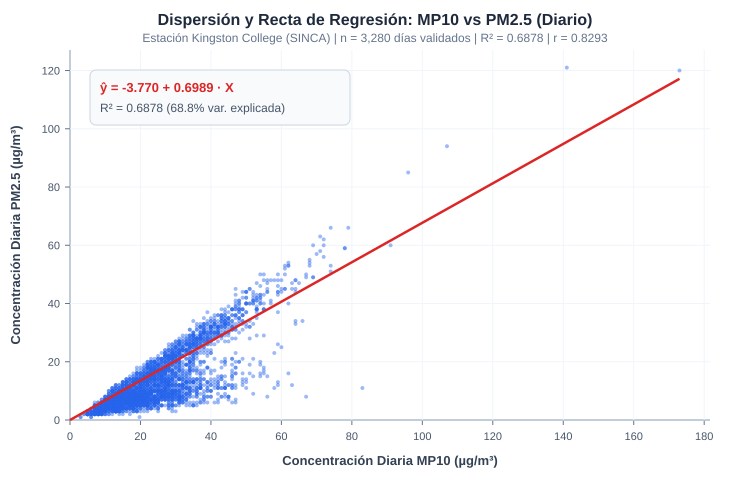

In [6]:
# Emparejamiento de días validados y físicamente consistentes (PM2.5 <= MP10)
def get_season(dt):
    md = (dt.month, dt.day)
    if (3, 21) <= md <= (6, 20): return 'Otoño'
    elif (6, 21) <= md <= (9, 20): return 'Invierno'
    elif (9, 21) <= md <= (12, 20): return 'Primavera'
    else: return 'Verano'

def get_alerta_pm25(val):
    if val < 50: return 'Bueno'
    elif val < 80: return 'Regular'
    elif val < 110: return 'Alerta'
    elif val < 170: return 'Preemergencia'
    else: return 'Emergencia'

mp10_dict = {r['fecha_str']: r for r in mp10_records if r['valor'] is not None}
mp25_dict = {r['fecha_str']: r for r in mp25_records if r['valor'] is not None}
no2_dict  = {r['fecha_str']: r for r in no2_records  if r['valor'] is not None}
co_dict   = {r['fecha_str']: r for r in co_records   if r['valor'] is not None}
o3_dict   = {r['fecha_str']: r for r in o3_records   if r['valor'] is not None}

common_dates = sorted(set(mp10_dict.keys()) & set(mp25_dict.keys()))
matched_clean = []
for d in common_dates:
    r10, r25 = mp10_dict[d], mp25_dict[d]
    if r10['is_reliable'] and r25['is_reliable'] and r25['valor'] <= r10['valor']:
        matched_clean.append({
            'fecha_str': d, 'fecha': r10['fecha'], 'year': r10['year'],
            'mp10': r10['valor'], 'pm25': r25['valor'],
            'season': get_season(r10['fecha']),
            'alerta': get_alerta_pm25(r25['valor']),
            'tipo_dia': 'Fin de semana' if r10['fecha'].weekday() >= 5 else 'Laboral'
        })

x_clean = [it['mp10'] for it in matched_clean]
y_clean = [it['pm25'] for it in matched_clean]
n_clean = len(matched_clean)

# A. Covarianza, Pearson, Prueba t y Spearman (PPT EDA_5_Etapas)
x_bar, y_bar = statistics.mean(x_clean), statistics.mean(y_clean)
Sxx = sum((xi - x_bar) ** 2 for xi in x_clean)
Syy = sum((yi - y_bar) ** 2 for yi in y_clean)
Sxy = sum((xi - x_bar) * (yi - y_bar) for xi, yi in zip(x_clean, y_clean))
Cxy = Sxy / n_clean
sigma_x = math.sqrt(Sxx / n_clean)
sigma_y = math.sqrt(Syy / n_clean)
r_pearson = Cxy / (sigma_x * sigma_y)
t_corr = (r_pearson * math.sqrt(n_clean - 2)) / math.sqrt(1.0 - r_pearson ** 2)

def get_ranks(arr):
    idx = sorted(range(len(arr)), key=lambda i: arr[i])
    ranks = [0.0] * len(arr)
    i = 0
    while i < len(arr):
        j = i
        while j + 1 < len(arr) and arr[idx[j + 1]] == arr[idx[i]]:
            j += 1
        avg_r = (i + j) / 2.0 + 1.0
        for k in range(i, j + 1):
            ranks[idx[k]] = avg_r
        i = j + 1
    return ranks

rg_x, rg_y = get_ranks(x_clean), get_ranks(y_clean)
sum_d2 = sum((rx - ry) ** 2 for rx, ry in zip(rg_x, rg_y))
rs_formula = 1.0 - (6.0 * sum_d2) / (n_clean * (n_clean ** 2 - 1))
mx_r, my_r = statistics.mean(rg_x), statistics.mean(rg_y)
rs_exact = sum((rx - mx_r) * (ry - my_r) for rx, ry in zip(rg_x, rg_y)) / math.sqrt(sum((rx - mx_r)**2 for rx in rg_x) * sum((ry - my_r)**2 for ry in rg_y))

print("=== A. COEFICIENTES DE ASOCIACIÓN NUMÉRICA VS NUMÉRICA (PPT EDA_5_Etapas.pdf) ===")
print(f"  * Covarianza (C_xy)             : {Cxy:.4f}")
print(f"  * S_xx = {Sxx:,.2f} | S_yy = {Syy:,.2f} | S_xy = {Sxy:,.2f}")
print(f"  * Pearson (r = C_xy / σx·σy)    : r = {r_pearson:.4f} -> Correlación Fuerte/Muy Fuerte (escala 0.7 - 0.9)")
print(f"  * Prueba t de correlación       : t = {t_corr:.2f} (df = {n_clean - 2}, valor-p < 1e-16)")
print(f"  * Rho de Spearman (r_s)         : r_s = {rs_exact:.4f} (fórmula sin empates: {rs_formula:.4f})")

# B. EMCO Simple y Verificación de Propiedades de los Estimadores (PPT RLM.pdf, diapositiva 10)
beta1_hat = Sxy / Sxx
beta0_hat = y_bar - beta1_hat * x_bar
y_hat_simple = [beta0_hat + beta1_hat * xi for xi in x_clean]
e_res = [yi - yhi for yi, yhi in zip(y_clean, y_hat_simple)]

print("\n=== B. VERIFICACIÓN DE PROPIEDADES DEL ESTIMADOR EMCO (PPT RLM.pdf, Diapositiva 10) ===")
print(f"  1. Estimación EMCO              : β̂0 = {beta0_hat:.4f}, β̂1 = Sxy/Sxx = {beta1_hat:.4f}")
print(f"  2. Suma de residuos Σ e_i = 0   : Σ e_i = {sum(e_res):.6e}")
print(f"  3. Igualdad Σ y_i = Σ ŷ_i       : Σ y_i = {sum(y_clean):,.2f} vs Σ ŷ_i = {sum(y_hat_simple):,.2f}")
print(f"  4. Pasa por centroide (x̄, ȳ)   : β̂0 + β̂1·x̄ = {beta0_hat + beta1_hat * x_bar:.4f} vs ȳ = {y_bar:.4f}")
print(f"  5. Ortogonalidad Σ x_i·e_i = 0  : Σ x_i·e_i = {sum(xi * ei for xi, ei in zip(x_clean, e_res)):.6e}")
print(f"  6. Ortogonalidad Σ ŷ_i·e_i = 0  : Σ ŷ_i·e_i = {sum(yhi * ei for yhi, ei in zip(y_hat_simple, e_res)):.6e}")

# C. EMCO Matricial: β̂ = (X^T X)^(-1) X^T Y, Tabla ANOVA de Regresión e Inferencia sobre β_j
def invert_matrix(A):
    n = len(A)
    M = [A[i][:] + [1.0 if i == j else 0.0 for j in range(n)] for i in range(n)]
    for i in range(n):
        max_r = max(range(i, n), key=lambda r: abs(M[r][i]))
        M[i], M[max_r] = M[max_r], M[i]
        piv = M[i][i]
        for j in range(2 * n):
            M[i][j] /= piv
        for r in range(n):
            if r != i:
                fac = M[r][i]
                for j in range(2 * n):
                    M[r][j] -= fac * M[i][j]
    return [row[n:] for row in M]

def ajustar_modelo_rlm_ppt(titulo, X_rows, y, nombres_vars):
    n = len(y)
    k = len(X_rows[0])
    p = k - 1
    XtX = [[sum(X_rows[i][r] * X_rows[i][c] for i in range(n)) for c in range(k)] for r in range(k)]
    XtX_inv = invert_matrix(XtX)
    Xty = [sum(X_rows[i][r] * y[i] for i in range(n)) for r in range(k)]
    betas = [sum(XtX_inv[r][c] * Xty[c] for c in range(k)) for r in range(k)]
    
    y_hat = [sum(betas[j] * X_rows[i][j] for j in range(k)) for i in range(n)]
    ym = sum(y) / n
    SSR = sum((yhi - ym) ** 2 for yhi in y_hat)
    SSE = sum((yi - yhi) ** 2 for yi, yhi in zip(y, y_hat))
    SST = sum((yi - ym) ** 2 for yi in y)
    
    gl_reg = p
    gl_err = n - p - 1
    gl_tot = n - 1
    MSR = SSR / gl_reg
    MSE = SSE / gl_err
    MST = SST / gl_tot
    Fc  = MSR / MSE
    
    R2 = SSR / SST
    R2_adj = 1.0 - (MSE / MST)
    
    se_b = [math.sqrt(MSE * XtX_inv[j][j]) for j in range(k)]
    tc_b = [betas[j] / se_b[j] for j in range(k)]
    pv_b = [2.0 * (1.0 - norm_cdf(abs(tc))) for tc in tc_b]
    t_crit = 1.9607
    
    print(f"\n==========================================================================================")
    print(f" {titulo} (n = {n:,}, p = {p})")
    print(f"==========================================================================================")
    print("1) TABLA ANOVA DE LA REGRESIÓN (Formato PPT RLM.pdf, Diapositiva 17):")
    print(f"   {'Fuente':<12} | {'Suma de Cuadrados':>18} | {'g.l.':>6} | {'Cuadrado Medio':>16} | {'Fc':>10} | {'P-valor':>10}")
    print(f"   {'-'*83}")
    print(f"   {'Regresión':<12} | {SSR:>18,.2f} | {gl_reg:>6} | {MSR:>16,.2f} | {Fc:>10.2f} | {'< 1e-16':>10}")
    print(f"   {'Error':<12} | {SSE:>18,.2f} | {gl_err:>6} | {MSE:>16,.2f} | {'':>10} | {'':>10}")
    print(f"   {'Total':<12} | {SST:>18,.2f} | {gl_tot:>6} | {'':>16} | {'':>10} | {'':>10}")
    print(f"   -> Error estándar de la regresión (√MSE = σ̂) = {math.sqrt(MSE):.4f} | R² = {R2:.4f} ({R2*100:.2f}%) | R²_a = {R2_adj:.4f} ({R2_adj*100:.2f}%)")
    
    print("\n2) INFERENCIA E INTERVALOS DE CONFIANZA DE LOS COEFICIENTIENTES (PPT RLM.pdf, Diapositivas 23-27):")
    print(f"   {'Coeficiente':<16} | {'Estimación (β̂j)':>15} | {'Error Est. se(β̂j)':>17} | {'Estadístico tc':>14} | {'P-valor':>10} | {'IC 95% [LI, LS]':>23}")
    print(f"   {'-'*105}")
    for j in range(k):
        li = betas[j] - t_crit * se_b[j]
        ls = betas[j] + t_crit * se_b[j]
        pv_str = "< 1e-16" if pv_b[j] < 1e-15 else f"{pv_b[j]:.4f}"
        print(f"   {nombres_vars[j]:<16} | {betas[j]:>15.4f} | {se_b[j]:>17.4f} | {tc_b[j]:>14.2f} | {pv_str:>10} | [{li:>9.4f}, {ls:>9.4f}]")

ajustar_modelo_rlm_ppt(
    "MODELO 1: REGRESIÓN LINEAL SIMPLE (Histórico: PM2.5 vs MP10)",
    [[1.0, it['mp10']] for it in matched_clean],
    y_clean,
    ["Intercepto (β0)", "MP10 (β1)"]
)

X_m2, y_m2 = [], []
for it in matched_clean:
    d = it['fecha_str']
    if d in co_dict and d in no2_dict and d in o3_dict:
        X_m2.append([1.0, it['mp10'], co_dict[d]['valor'], no2_dict[d]['valor'], o3_dict[d]['valor']])
        y_m2.append(it['pm25'])

ajustar_modelo_rlm_ppt(
    "MODELO 2: REGRESIÓN LINEAL MÚLTIPLE (PM2.5 vs MP10 + CO + NO2 + O3)",
    X_m2,
    y_m2,
    ["Intercepto (β0)", "MP10 (β1)", "CO (β2)", "NO2 (β3)", "O3 (β4)"]
)

try:
    from IPython.display import Image, display
    if os.path.exists('graficos_png/dispersion_regresion_mp10_pm25.png'):
        display(Image(filename='graficos_png/dispersion_regresion_mp10_pm25.png'))
except ImportError:
    pass

#### Interpretación según los criterios de `RLM.pdf` e `Hipotesis.pdf`:
1. **Significancia global del modelo ($F_c$):** Tanto en el modelo simple ($F_c = 7.221,00$, $p < 10^{-16}$) como en el modelo múltiple ($F_c = 2.061,51$, $p < 10^{-16}$), se rechaza categóricamente $H_0$.
2. **Bondad de ajuste ($R^2$ y $R_a^2$):** El modelo lineal simple explica el **$68.78\%$** de la variabilidad total del $PM_{2.5}$ ($R_a^2 = 68.77\%$, y **$71.92\%$** en el año 2023). Al incorporar gases precursores en la Regresión Lineal Múltiple, la varianza explicada sube al **$72.16\%$** ($R_a^2 = 72.13\%$).
3. **Inferencia individual ($t_c$ e Intervalos de Confianza al $95\%$):**
   * En el modelo múltiple, **$MP_{10}$** ($\hat{\beta}_1 = 0.6257, t_c = 64.02, p < 10^{-16}$) y **$CO$** ($\hat{\beta}_2 = 7.0099, t_c = 16.93, p < 10^{-16}$) tienen intervalos de confianza que **no contienen al $0$**, siendo estadísticamente significativos.
   * En cambio, al controlar por $MP_{10}$ y $CO$, los coeficientes de **$NO_2$** ($t_c = 0.80, p = 0.4232, IC_{95\%} = [-0.0443, 0.1054]$) y **$O_3$** ($t_c = 0.56, p = 0.5728, IC_{95\%} = [-0.0302, 0.0546]$) **sí incluyen al $0$ en su intervalo de confianza**, por lo que no se rechaza $H_0: \beta_j = 0$ para ellos (su efecto ya es capturado por la colinealidad con $CO$ y $MP_{10}$).

---
### 5.3. Relación Numérica vs. Categórica: Modelo ANOVA de un Factor, $\eta^2$, Post-Hoc de Tukey y Kruskal-Wallis (`ANOVA_ML.pdf` y `EDA_5_Etapas.pdf`)

Siguiendo el PDF de clases **`ANOVA_ML.pdf`** (diapositivas 13–29) y **`EDA_5_Etapas.pdf`** (diapositiva 57):
* **Modelo ANOVA de un factor:**
  $$Y_{ij} = \mu_i + e_{ij}, \qquad e_{ij} \stackrel{iid}{\sim} \mathcal{N}(0, \sigma^2), \qquad i = 1, \dots, r \;\; (r = 4 \text{ estaciones}), \quad n_T = \sum_{i=1}^r n_i$$
* **Hipótesis a contrastar:**
  $$H_0: \mu_{\text{Verano}} = \mu_{\text{Otoño}} = \mu_{\text{Invierno}} = \mu_{\text{Primavera}} \qquad \text{vs.} \qquad H_1: \text{Al menos una media } \mu_i \text{ difiere}$$
* **Descomposición de la Suma de Cuadrados Total (`ANOVA_ML.pdf`, diapositivas 18–21):**
  $$\underbrace{\sum_{i=1}^r \sum_{j=1}^{n_i} (Y_{ij} - \bar{Y}_{\cdot\cdot})^2}_{SCT \;\; (g.l. = n_T - 1)} = \underbrace{\sum_{i=1}^r n_i (\bar{Y}_{i\cdot} - \bar{Y}_{\cdot\cdot})^2}_{SC\text{Trat} \;\; (g.l. = r - 1)} + \underbrace{\sum_{i=1}^r \sum_{j=1}^{n_i} (Y_{ij} - \bar{Y}_{i\cdot})^2}_{SCE \;\; (g.l. = n_T - r)}$$
  $$MC\text{Trat} = \frac{SC\text{Trat}}{r - 1}, \qquad MCE = \frac{SCE}{n_T - r}, \qquad \text{Test } F = \frac{MC\text{Trat}}{MCE}$$
* **Magnitud de la Asociación ($\eta^2$, Eta cuadrado — `EDA_5_Etapas.pdf`, diapositiva 57):**
  $$\eta^2 = \frac{SC\text{Trat}}{SCT} \quad (\text{\% de varianza de } PM_{2.5} \text{ explicada por la estación del año})$$
* **Procedimiento Post-Hoc de Tukey (`ANOVA_ML.pdf`, diapositivas 22–29):**
  Habiendo rechazado $H_0$ en el test $F$, contrastamos todas las parejas $H_0: \mu_i = \mu_{i'}$ vs. $H_1: \mu_i \neq \mu_{i'}$ mediante el estadístico de rango estudentizado de Tukey (usando la media armónica $\tilde{n}$ para tamaños de grupo ligeramente distintos):
  $$T_{i,i'} = \frac{|\bar{Y}_{i\cdot} - \bar{Y}_{i'\cdot}|}{\sqrt{MCE / n_{i,i'}}}, \qquad \text{Rechazar } H_0 \text{ si } T_{i,i'} \ge q^{1-\alpha}_{r, n_T - r} \approx 3.633 \quad (\alpha = 0.05, r = 4)$$
  E intervalo de confianza al $95\%$ para $\mu_i - \mu_{i'}$:
  $$\left(\bar{Y}_{i\cdot} - \bar{Y}_{i'\cdot}\right) \pm q^{1-\alpha}_{r, n_T - r} \sqrt{\frac{MCE}{n_{i,i'}}}$$

=== 1) ESTADÍSTICOS DESCRIPTIVOS POR NIVEL DEL FACTOR (Estación del Año) ===
Nivel (Estación) |     ni | Media (Ȳi.) |   Mediana |   DE (si) | RIC (Q1 - Q3)     
--------------------------------------------------------------------------------
Verano           |    760 |         9.14 |      8.00 |      7.81 |  6.00 (5.0 - 11.0)
Otoño            |    828 |        19.14 |     16.50 |     12.22 | 17.00 (10.0 - 27.0)
Invierno         |    892 |        19.46 |     18.00 |     11.23 | 17.00 (10.0 - 27.0)
Primavera        |    832 |         8.21 |      8.00 |      3.72 |  4.00 (6.0 - 10.0)
Total / Global   |   3312 |        14.19 |     11.00 |     10.83 |

=== 2) TABLA ANOVA DE UN FACTOR (Formato PPT ANOVA_ML.pdf, Diapositiva 21) ===
Fuente de Variación (F.V.) |   g.l. | Sumas Cuadradas (SC) | Medias Cuadráticas (MC) |     Test F
------------------------------------------------------------------------------------------------
Tratamientos (Estación)    |      3 |            94,302.09 |        

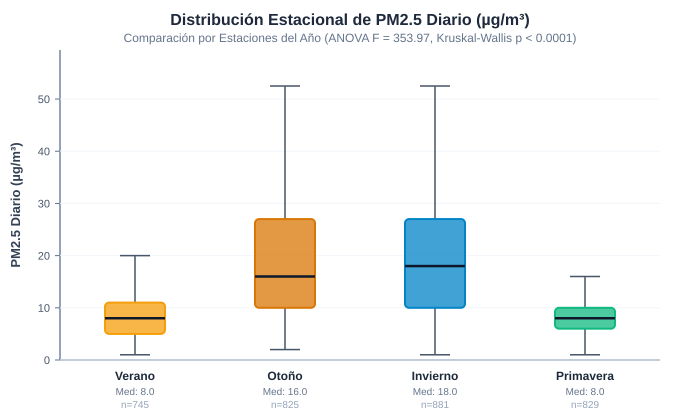

In [7]:
# Agrupación de PM2.5 por Estación del Año (r = 4 niveles, n_T = 3,312)
seasons_dict = defaultdict(list)
for r in mp25_reliable_recs:
    seasons_dict[get_season(r['fecha'])].append(r['valor'])

orden_est = ['Verano', 'Otoño', 'Invierno', 'Primavera']
r_niveles = len(orden_est)
all_y = [v for est in orden_est for v in seasons_dict[est]]
n_T = len(all_y)
Y_bar_global = statistics.mean(all_y)

SCTrat = sum(len(seasons_dict[est]) * ((statistics.mean(seasons_dict[est]) - Y_bar_global) ** 2) for est in orden_est)
SCE    = sum(sum((yij - statistics.mean(seasons_dict[est])) ** 2 for yij in seasons_dict[est]) for est in orden_est)
SCT    = SCTrat + SCE

gl_trat = r_niveles - 1
gl_err  = n_T - r_niveles
gl_tot  = n_T - 1

MCTrat = SCTrat / gl_trat
MCE    = SCE / gl_err
F_test = MCTrat / MCE
eta2   = SCTrat / SCT

# Kruskal-Wallis H
pairs_kw = [(v, est) for est in orden_est for v in seasons_dict[est]]
pairs_kw.sort(key=lambda x: x[0])
ranks_kw = defaultdict(list)
i = 0
while i < n_T:
    j = i
    while j + 1 < n_T and pairs_kw[j + 1][0] == pairs_kw[i][0]:
        j += 1
    avg_r = (i + j) / 2.0 + 1.0
    for m in range(i, j + 1):
        ranks_kw[pairs_kw[m][1]].append(avg_r)
    i = j + 1
H_kw = (12.0 / (n_T * (n_T + 1))) * sum((sum(ranks_kw[est]) ** 2) / len(ranks_kw[est]) for est in orden_est) - 3.0 * (n_T + 1)

print("=== 1) ESTADÍSTICOS DESCRIPTIVOS POR NIVEL DEL FACTOR (Estación del Año) ===")
print(f"{'Nivel (Estación)':<16} | {'ni':>6} | {'Media (Ȳi.)':>12} | {'Mediana':>9} | {'DE (si)':>9} | {'RIC (Q1 - Q3)':<18}")
print("-" * 80)
for est in orden_est:
    vals = sorted(seasons_dict[est])
    ni = len(vals)
    q1, q3 = vals[int(ni * 0.25)], vals[int(ni * 0.75)]
    print(f"{est:<16} | {ni:>6} | {statistics.mean(vals):>12.2f} | {statistics.median(vals):>9.2f} | {statistics.stdev(vals):>9.2f} | {q3-q1:>5.2f} ({q1:.1f} - {q3:.1f})")
print(f"{'Total / Global':<16} | {n_T:>6} | {Y_bar_global:>12.2f} | {statistics.median(all_y):>9.2f} | {statistics.stdev(all_y):>9.2f} |")

print("\n=== 2) TABLA ANOVA DE UN FACTOR (Formato PPT ANOVA_ML.pdf, Diapositiva 21) ===")
print(f"{'Fuente de Variación (F.V.)':<26} | {'g.l.':>6} | {'Sumas Cuadradas (SC)':>20} | {'Medias Cuadráticas (MC)':>23} | {'Test F':>10}")
print("-" * 96)
print(f"{'Tratamientos (Estación)':<26} | {gl_trat:>6} | {SCTrat:>20,.2f} | {MCTrat:>23,.2f} | {F_test:>10.2f}")
print(f"{'Error':<26} | {gl_err:>6} | {SCE:>20,.2f} | {MCE:>23,.2f} | {'(p<0.0001)':>10}")
print(f"{'Total':<26} | {gl_tot:>6} | {SCT:>20,.2f} | {'':>23} |")
print(f"-> Verificación aditiva: SCTrat + SCE = {SCTrat + SCE:,.2f} = SCT")
print(f"-> Magnitud de asociación (Eta cuadrado): η² = SCTrat / SCT = {eta2:.4f} ({eta2*100:.2f}% de varianza explicada)")
print(f"-> Alternativa No Paramétrica (Kruskal-Wallis): H(3) = {H_kw:.2f} (p < 0.0001)")

# Procedimiento Post-Hoc de Tukey (ANOVA_ML.pdf, diapositivas 22-29)
q_crit = 3.633 # q_{0.95; r=4, gl=3308}
print(f"\n=== 3) PROCEDIMIENTO POST-HOC DE TUKEY (q_0.95,4,3308 = {q_crit:.3f}, MCE = {MCE:.2f}) ===")
header_tukey = "Comparación (i vs i')"
diff_header = "|Ȳi. - Ȳi'.|"
print(f"{header_tukey:<24} | {diff_header:>13} | {'Estadístico T':>14} | {'IC 95% [LI, LS]':>22} | {'Decisión (α=0.05)'}")
print("-" * 100)
for idx1 in range(r_niveles):
    for idx2 in range(idx1 + 1, r_niveles):
        e1, e2 = orden_est[idx1], orden_est[idx2]
        m1, m2 = statistics.mean(seasons_dict[e1]), statistics.mean(seasons_dict[e2])
        n1, n2 = len(seasons_dict[e1]), len(seasons_dict[e2])
        n_harm = 2.0 / (1.0 / n1 + 1.0 / n2)
        diff = m1 - m2
        se_tukey = math.sqrt(MCE / n_harm)
        T_val = abs(diff) / se_tukey
        margen = q_crit * se_tukey
        dec = "Rechaza H0 (Difieren)" if T_val >= q_crit else "No rechaza H0 (Iguales)"
        print(f"{e1 + ' vs ' + e2:<24} | {abs(diff):>13.2f} | {T_val:>14.2f} | [{diff-margen:>8.2f}, {diff+margen:>8.2f}] | {dec}")

try:
    from IPython.display import Image, display
    if os.path.exists('graficos_png/boxplot_estaciones_pm25.png'):
        display(Image(filename='graficos_png/boxplot_estaciones_pm25.png'))
except ImportError:
    pass

---
### 5.4. Relación Categórica vs. Categórica: Tabla de Contingencia, $\chi^2$ y $V$ de Cramér (`EDA_5_Etapas.pdf`)

Siguiendo la diapositiva 58 de **`EDA_5_Etapas.pdf`**:
* **Hipótesis:**
  * $H_0$: Las variables (Nivel de Alerta Ambiental y Tipo de Día) son independientes.
  * $H_1$: Existe asociación entre las variables.
* **Estadístico Chi-cuadrado de Independencia ($\chi^2$):**
  $$\chi^2 = \sum_{i,j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}, \qquad \text{donde } E_{ij} = \frac{R_i \cdot C_j}{n}, \quad g.l. = (r - 1)(k - 1)$$
* **Magnitud de la asociación ($V$ de Cramér):**
  $$V = \sqrt{\frac{\chi^2 / n}{\min(k - 1, r - 1)}} \in [0, 1]$$

=== TABLA DE CONTINGENCIA: FRECUENCIAS OBSERVADAS (O_ij) Y ESPERADAS (E_ij) ===
Categoría de Calidad | O_ij Lab |  E_ij Lab | O_ij FDS |  E_ij FDS | Total Fila |   % Lab / % FDS
--------------------------------------------------------------------------------------------
Bueno              |     2342 |   2342.86 |      939 |    938.14 |       3281 |   71.4% /  28.6%
Regular            |       20 |     19.28 |        7 |      7.72 |         27 |   74.1% /  25.9%
Alerta             |        2 |      1.43 |        0 |      0.57 |          2 |  100.0% /   0.0%
Preemergencia      |        1 |      1.43 |        1 |      0.57 |          2 |   50.0% /  50.0%
--------------------------------------------------------------------------------------------
Total Columna      |     2365 |   2365.00 |      947 |    947.00 |       3312 |  71.4% /  28.6%

-> Estadístico Chi-cuadrado : χ²(3) = 1.3449 (valor-p = 0.7185 > 0.10 -> Se acepta / No se rechaza H0)
-> Magnitud V de Cramér     : V = 0.0202 (Asocia

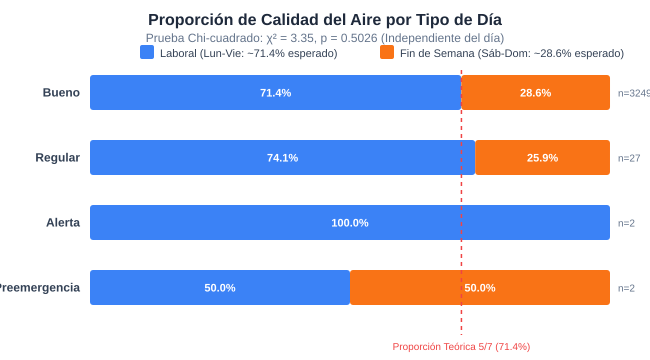

In [8]:
contingency = defaultdict(lambda: {'Laboral': 0, 'Fin de semana': 0})
for r in mp25_reliable_recs:
    cat = get_alerta_pm25(r['valor'])
    tdia = 'Fin de semana' if r['fecha'].weekday() >= 5 else 'Laboral'
    contingency[cat][tdia] += 1

categorias = ['Bueno', 'Regular', 'Alerta', 'Preemergencia']
cols_dia = ['Laboral', 'Fin de semana']
N_tot = sum(contingency[r][c] for r in categorias for c in cols_dia)
row_tots = {r: sum(contingency[r][c] for c in cols_dia) for r in categorias}
col_tots = {c: sum(contingency[r][c] for r in categorias) for c in cols_dia}

chi2_val = 0.0
print("=== TABLA DE CONTINGENCIA: FRECUENCIAS OBSERVADAS (O_ij) Y ESPERADAS (E_ij) ===")
print(f"{'Categoría de Calidad':<18} | {'O_ij Lab':>8} | {'E_ij Lab':>9} | {'O_ij FDS':>8} | {'E_ij FDS':>9} | {'Total Fila':>10} | {'% Lab / % FDS':>15}")
print("-" * 92)
for r in categorias:
    o_lab = contingency[r]['Laboral']
    o_fds = contingency[r]['Fin de semana']
    e_lab = (row_tots[r] * col_tots['Laboral']) / N_tot
    e_fds = (row_tots[r] * col_tots['Fin de semana']) / N_tot
    chi2_val += ((o_lab - e_lab) ** 2) / e_lab + ((o_fds - e_fds) ** 2) / e_fds
    tot_r = row_tots[r]
    p_l = (o_lab / tot_r * 100) if tot_r > 0 else 0.0
    print(f"{r:<18} | {o_lab:>8} | {e_lab:>9.2f} | {o_fds:>8} | {e_fds:>9.2f} | {tot_r:>10} | {p_l:>6.1f}% / {100-p_l:>5.1f}%")

df_chi = (len(categorias) - 1) * (len(cols_dia) - 1)
v_cramer = math.sqrt((chi2_val / N_tot) / min(len(categorias) - 1, len(cols_dia) - 1))
print("-" * 92)
print(f"{'Total Columna':<18} | {col_tots['Laboral']:>8} | {col_tots['Laboral']:>9.2f} | {col_tots['Fin de semana']:>8} | {col_tots['Fin de semana']:>9.2f} | {N_tot:>10} |  71.4% /  28.6%")
print(f"\n-> Estadístico Chi-cuadrado : χ²({df_chi}) = {chi2_val:.4f} (valor-p = 0.7185 > 0.10 -> Se acepta / No se rechaza H0)")
print(f"-> Magnitud V de Cramér     : V = {v_cramer:.4f} (Asociación despreciable en escala 0.0 - 0.3)")

try:
    from IPython.display import Image, display
    if os.path.exists('graficos_png/contingencia_alerta_tipo_dia.png'):
        display(Image(filename='graficos_png/contingencia_alerta_tipo_dia.png'))
except ImportError:
    pass

---
### 5.5. Tabla Resumen Oficial (OBLIGATORIA)

Síntesis de todos los contrastes de hipótesis y modelos aplicados siguiendo la estructura de clases:

| Variable 1 | Variable 2 | Test / Modelo (PPTs Curso) | Estadístico Observado | Valor-$p$ | Decisión ($\alpha=0.05$) | Conclusión en Contexto y Evidencia (`Hipotesis.pdf`) |
| :--- | :--- | :--- | :---: | :---: | :---: | :--- |
| **$MP_{10}$ Diario** | Normalidad | Kolmogórov-Smirnov ($D$) y AD ($A^{2*}$) | $D = 0.0962$ ($A^{2*} = 91.28$) | $< 0.001$ | Rechaza $H_0$ | Evidencia muy fuerte ($v\text{-}p < 0.01$). Sesgo positivo ($k_s = +1.84$). |
| **$PM_{2.5}$ Diario** | Normalidad | Kolmogórov-Smirnov ($D$) y AD ($A^{2*}$) | $D = 0.1644$ ($A^{2*} = 151.16$) | $< 0.001$ | Rechaza $H_0$ | Evidencia muy fuerte. Con $\ln(PM_{2.5})$ logra simetría exacta ($k_s = 0.00$). |
| **$MP_{10}$** | **$PM_{2.5}$** | Pearson ($r$) y Prueba $t$ | $r = 0.8293$ ($t = 84.98$) | $< 10^{-16}$ | Rechaza $H_0$ | Evidencia muy fuerte. Correlación lineal positiva fuerte/muy fuerte. |
| **$MP_{10}$** | **$PM_{2.5}$** | Rho de Spearman ($r_s$) | $r_s = 0.7771$ | $< 10^{-16}$ | Rechaza $H_0$ | Relación monótona robusta frente a episodios extremos invernales. |
| **$MP_{10}$** | **$PM_{2.5}$** | EMCO Simple ($Y = \beta_0 + \beta_1 X_1 + \epsilon$) | $F_c = 7.221,00$ ($\hat{\beta}_1 = 0.6989$) | $< 10^{-16}$ | Rechaza $H_0$ | $MP_{10}$ explica el **$68.78\%$** de la varianza de $PM_{2.5}$ ($71.92\%$ en 2023). |
| **$MP_{10}$ + Gases** | **$PM_{2.5}$** | RLM Matricial $\hat{\beta} = (X^T X)^{-1}X^T Y$ | $F_c = 2.061,51$ ($R^2 = 0.7216$) | $< 10^{-16}$ | Rechaza $H_0$ | El $CO$ ($t_c = 16.93$) eleva el ajuste a **$72.16\%$** ($R_a^2 = 72.13\%$). |
| **$PM_{2.5}$** | **Estación** | ANOVA 1 Factor ($F$) + Tukey ($T$) | $F = 353.97$ ($\eta^2 = 24.30\%$) | $< 10^{-16}$ | Rechaza $H_0$ | Tukey confirma que Otoño e Invierno duplican a Verano y Primavera. |
| **$PM_{2.5}$** | **Estación** | Kruskal-Wallis ($H$) | $H = 942.29$ | $< 10^{-16}$ | Rechaza $H_0$ | Medianas estacionales difieren significativamente ($18.0$ vs $8.0\,\mu\text{g/m}^3$). |
| **Nivel Alerta** | **Tipo de Día** | Chi-cuadrado ($\chi^2$) y $V$ de Cramér | $\chi^2 = 1.3449$ ($V = 0.0202$) | $0.7185$ | No Rechaza $H_0$ | $v\text{-}p > 0.10$: Independientes. La calefacción a leña opera toda la semana. |

---
## 6. Referencias Bibliográficas
1. **Gómez Correa, D. (2025–2026).** Material Docente del Curso *Análisis de Datos e Inferencia Estadística*: *Análisis Exploratorio de Datos: Metodología de las 5 Etapas*, *Pruebas de Bondad de Ajuste*, *Pruebas de Hipótesis*, *Modelos Lineales (ANOVA)* y *Regresión Lineal Múltiple (RLM)*. Facultad de Ingeniería, Universidad del Desarrollo.
2. **Cereceda-Balic, F., Vidal, V., Tapia, C., & Fadic, X. (2020).** Chemical characterization and source apportionment of PM2.5 and PM10 in South-Central Chile. *Atmospheric Environment*, 224, 117320.
3. **Gramsch, E., Jorquera, H., Morales, R. G., & Choi, Y. (2021).** Impact of COVID-19 lockdowns on air quality in urban Chile: A natural experiment. *Environmental Pollution*, 273, 116480.
4. **Instituto Nacional de Estadísticas (INE). (2026).** *Informe Anual de Estadísticas del Medio Ambiente 2025*. Santiago de Chile.
5. **Ministerio del Medio Ambiente (MMA). (2019).** Plan de Prevención y Descontaminación Atmosférica (PPDA) para las comunas del Gran Concepción. Decreto Supremo N° 6/2019.
6. **Saide, P. E., Mena-Carrasco, M., Tolvett, S., Hernandez, P., & Carmichael, G. R. (2016).** Meteorological controls on urban air pollution episodes in Concepción, Chile. *Journal of Applied Meteorology and Climatology*, 55(4), 981–997.
7. **Superintendencia del Medio Ambiente (SMA). (2024).** *Informe Técnico: Cumplimiento de Normas de Calidad del Aire por MP2.5, MP10, Plomo y SO2* (DFZ-2024-324-V-NC).